In [23]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPU devices:", tf.config.list_physical_devices("GPU"))

if not tf.config.list_physical_devices("GPU"):
    print("No GPU detected. You can still run this notebook, but training will be slower.")

TensorFlow version: 2.21.0
Available GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [25]:
!pip -q install kaggle

from google.colab import files
uploaded = files.upload()  # Select kaggle.json

import os
import shutil

# Find if any uploaded file matches the kaggle credentials JSON pattern
uploaded_key = None
for filename in uploaded.keys():
    if "kaggle" in filename.lower() and filename.endswith(".json"):
        uploaded_key = filename
        break

if not uploaded_key:
    raise FileNotFoundError("Please upload the file named kaggle.json")

# If it was renamed to something like 'kaggle (1).json', rename it back to 'kaggle.json'
if uploaded_key != "kaggle.json":
    if os.path.exists("kaggle.json"):
        os.remove("kaggle.json")
    os.rename(uploaded_key, "kaggle.json")

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

# Remove the uploaded copy from the working folder.
os.remove("kaggle.json")
print("Kaggle API token configured securely.")

Saving kaggle.json to kaggle (2).json
Kaggle API token configured securely.


In [26]:
!mkdir -p /content/dataset
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/dataset --force
!unzip -q -o /content/dataset/chest-xray-pneumonia.zip -d /content/dataset
print("Dataset downloaded and extracted.")

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [03:39<00:00, 11.2MB/s]

Dataset downloaded and extracted.


In [27]:
from pathlib import Path

root = Path("/content/dataset")
candidates = [p for p in root.rglob("train") if p.is_dir() and (p.parent / "test").is_dir()]
if not candidates:
    raise FileNotFoundError("Could not find train and test folders. Check that the Kaggle dataset extracted correctly.")

DATA_DIR = candidates[0].parent
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
VAL_DIR = DATA_DIR / "val"

print("Dataset directory:", DATA_DIR)
print("Train exists:", TRAIN_DIR.exists())
print("Test exists:", TEST_DIR.exists())
print("Validation folder exists:", VAL_DIR.exists())
print("Train classes:", [p.name for p in TRAIN_DIR.iterdir() if p.is_dir()])
print("Test classes:", [p.name for p in TEST_DIR.iterdir() if p.is_dir()])

Dataset directory: /content/dataset/chest_xray
Train exists: True
Test exists: True
Validation folder exists: True
Train classes: ['NORMAL', 'PNEUMONIA']
Test classes: ['NORMAL', 'PNEUMONIA']


In [28]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications import MobileNetV2, DenseNet121, VGG16

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 8
FINE_TUNE_EPOCHS = 3

tf.keras.utils.set_random_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

MODEL_DIR = Path("/content/models")
RESULT_DIR = Path("/content/results")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration ready.")

Configuration ready.


In [29]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="binary",
    color_mode="rgb"
)

CLASS_NAMES = train_ds.class_names
print("Class order:", CLASS_NAMES)
assert CLASS_NAMES == ["NORMAL", "PNEUMONIA"], f"Unexpected class order: {CLASS_NAMES}"

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# Extract test labels once. shuffle=False ensures predictions and labels stay aligned.
y_true = np.concatenate([labels.numpy().ravel() for _, labels in test_ds]).astype(int)
print("Number of test images:", len(y_true))
print("Test class counts:", dict(zip(*np.unique(y_true, return_counts=True))))

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Found 5216 files belonging to 2 classes.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
Class order: ['NORMAL', 'PNEUMONIA']
Number of test images: 624
Test class counts: {np.int64(0): np.int64(234), np.int64(1): np.int64(390)}


In [30]:
train_labels = np.concatenate([labels.numpy().ravel() for _, labels in train_ds]).astype(int)
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=train_labels
)
CLASS_WEIGHTS = {0: float(class_weights_array[0]), 1: float(class_weights_array[1])}
print("Class weights:", CLASS_WEIGHTS)

Class weights: {0: 1.9261511728931364, 1: 0.675296984465428}


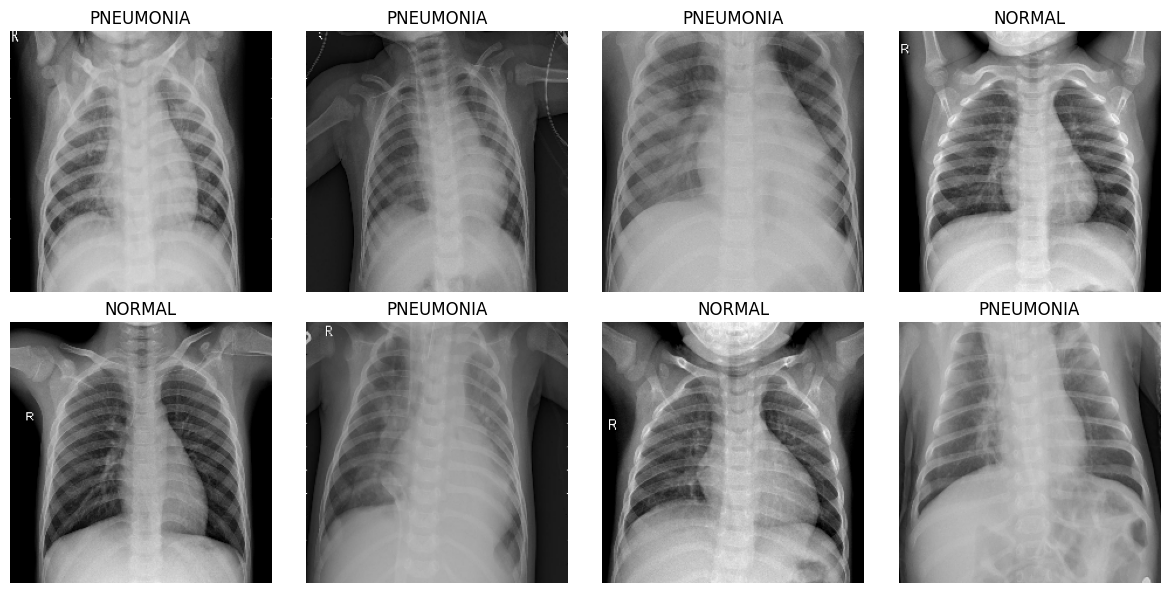

In [31]:
plt.figure(figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i in range(min(8, len(images))):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[int(labels[i].numpy()[0])])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [32]:
augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.08)
], name="data_augmentation")

@tf.keras.utils.register_keras_serializable(package="PneumoVision")
def preprocess_mobilenet(x):
    return tf.keras.applications.mobilenet_v2.preprocess_input(x)

@tf.keras.utils.register_keras_serializable(package="PneumoVision")
def preprocess_densenet(x):
    return tf.keras.applications.densenet.preprocess_input(x)

@tf.keras.utils.register_keras_serializable(package="PneumoVision")
def preprocess_vgg16(x):
    return tf.keras.applications.vgg16.preprocess_input(x)

In [33]:
def build_custom_cnn():
    inputs = layers.Input(shape=(224, 224, 3), name="xray_input")
    x = augmentation(inputs)
    x = layers.Rescaling(1.0 / 255.0)(x)

    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_probability")(x)

    return models.Model(inputs, outputs, name="Custom_CNN")

In [34]:
def build_transfer_model(model_name):
    inputs = layers.Input(shape=(224, 224, 3), name="xray_input")
    x = augmentation(inputs)

    if model_name == "MobileNetV2":
        x = layers.Lambda(preprocess_mobilenet, name="application_preprocessing")(x)
        backbone = MobileNetV2(
            weights="imagenet", include_top=False,
            input_shape=(224, 224, 3), name="backbone"
        )
    elif model_name == "DenseNet121":
        x = layers.Lambda(preprocess_densenet, name="application_preprocessing")(x)
        backbone = DenseNet121(
            weights="imagenet", include_top=False,
            input_shape=(224, 224, 3), name="backbone"
        )
    elif model_name == "VGG16":
        x = layers.Lambda(preprocess_vgg16, name="application_preprocessing")(x)
        backbone = VGG16(
            weights="imagenet", include_top=False,
            input_shape=(224, 224, 3), name="backbone"
        )
    else:
        raise ValueError("Unknown transfer-learning model: " + model_name)

    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_probability")(x)

    return models.Model(inputs, outputs, name=model_name)

In [35]:
def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

def train_one_model(model, model_name):
    model_path = MODEL_DIR / f"{model_name}.keras"

    compile_model(model, 1e-4)
    callbacks = [
        ModelCheckpoint(
            filepath=str(model_path),
            monitor="val_auc",
            mode="max",
            save_best_only=True,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

    print(f"\nTraining {model_name}")
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        class_weight=CLASS_WEIGHTS,
        callbacks=callbacks
    )

    if model_name in ["MobileNetV2", "DenseNet121", "VGG16"]:
        print(f"Fine-tuning {model_name}")
        backbone = model.get_layer("backbone")
        backbone.trainable = True

        # Keep most pretrained layers frozen; fine-tune only the final layers.
        for layer in backbone.layers[:-20]:
            layer.trainable = False
        for layer in backbone.layers:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False

        compile_model(model, 1e-5)
        fine_tune_callbacks = [
            ModelCheckpoint(
                filepath=str(model_path),
                monitor="val_auc",
                mode="max",
                save_best_only=True,
                verbose=1
            ),
            EarlyStopping(
                monitor="val_auc",
                mode="max",
                patience=2,
                restore_best_weights=True,
                verbose=1
            )
        ]
        fine_history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=FINE_TUNE_EPOCHS,
            class_weight=CLASS_WEIGHTS,
            callbacks=fine_tune_callbacks
        )
    else:
        fine_history = None

    # Load the best saved checkpoint, not simply the last epoch.
    best_model = tf.keras.models.load_model(str(model_path))
    return best_model, history, fine_history

In [36]:
model_builders = {
    "Custom_CNN": build_custom_cnn,
    "MobileNetV2": lambda: build_transfer_model("MobileNetV2"),
    "DenseNet121": lambda: build_transfer_model("DenseNet121"),
    "VGG16": lambda: build_transfer_model("VGG16")
}

trained_models = {}
histories = {}
fine_tune_histories = {}

for model_name, builder in model_builders.items():
    model = builder()
    trained_model, history, fine_history = train_one_model(model, model_name)
    trained_models[model_name] = trained_model
    histories[model_name] = history
    fine_tune_histories[model_name] = fine_history

print("\nAll models trained and saved.")
print("Saved model files:", [p.name for p in MODEL_DIR.glob("*.keras")])


Training Custom_CNN
Epoch 1/8
278/278 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.7917 - auc: 0.8920 - loss: 0.3980 - precision: 0.9424 - recall: 0.7579
Epoch 1: val_auc improved from None to 0.48395, saving model to /content/models/Custom_CNN.keras

Epoch 1: finished saving model to /content/models/Custom_CNN.keras
278/278 ━━━━━━━━━━━━━━━━━━━━ 47s 148ms/step - accuracy: 0.8455 - auc: 0.9311 - loss: 0.3304 - precision: 0.9616 - recall: 0.8242 - val_accuracy: 0.7570 - val_auc: 0.4840 - val_loss: 1.5557 - val_precision: 0.7570 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/8
277/278 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.9028 - auc: 0.9618 - loss: 0.2487 - precision: 0.9754 - recall: 0.8896
Epoch 2: val_auc improved from 0.48395 to 0.70395, saving model to /content/models/Custom_CNN.keras

Epoch 2: finished saving model to /content/models/Custom_CNN.keras
278/278 ━━━━━━━━━━━━━━━━━━━━ 41s 148ms/step - accuracy: 0.9044 - auc: 0.9637 - loss: 0.2385 - precision: 0.9

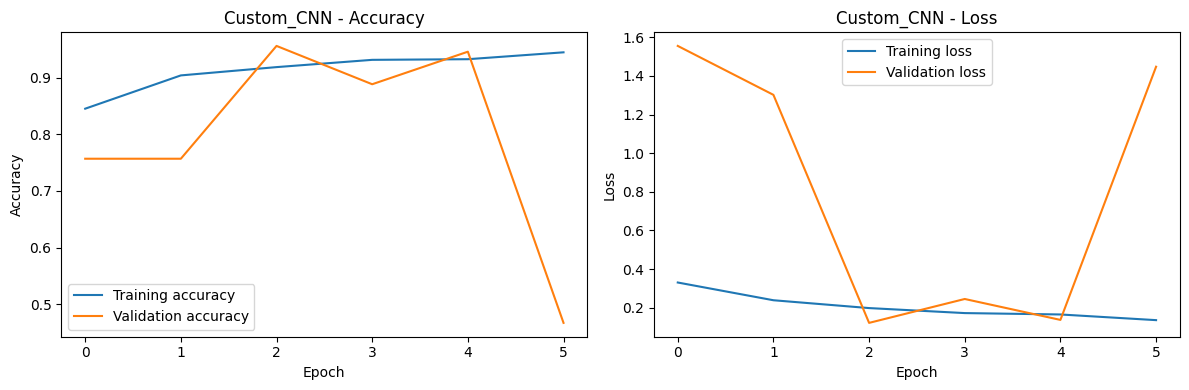

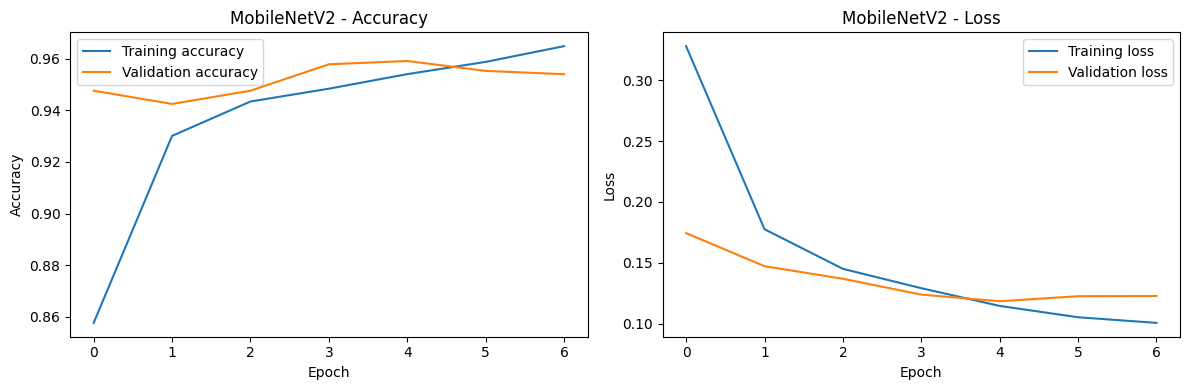

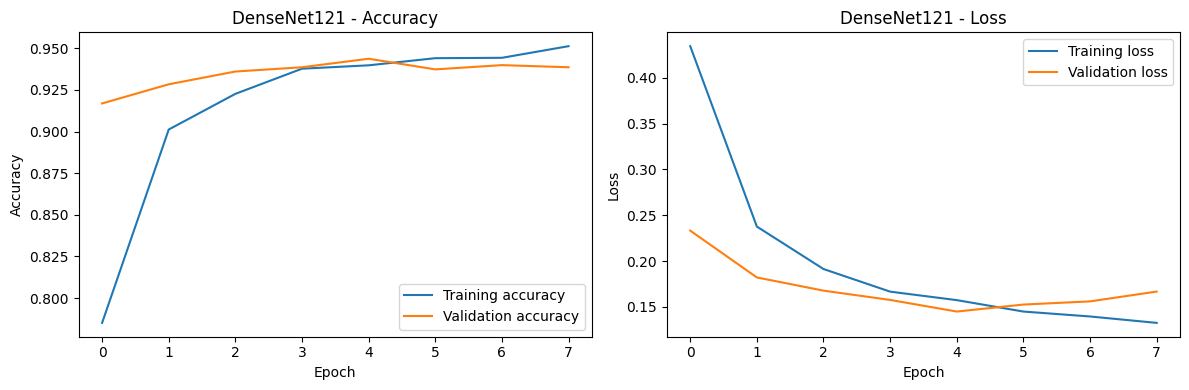

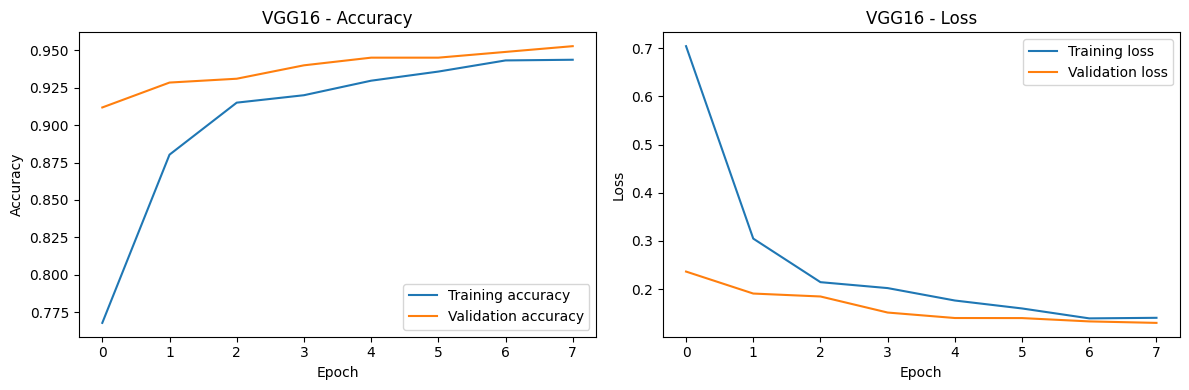

In [37]:
for name, history in histories.items():
    hist = history.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(hist["accuracy"], label="Training accuracy")
    axes[0].plot(hist["val_accuracy"], label="Validation accuracy")
    axes[0].set_title(f"{name} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(hist["loss"], label="Training loss")
    axes[1].plot(hist["val_loss"], label="Validation loss")
    axes[1].set_title(f"{name} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [38]:
all_metrics = []
all_probabilities = {}

for name, model in trained_models.items():
    print(f"\nEvaluating: {name}")
    probabilities = model.predict(test_ds, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    metrics_row = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1-score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }
    all_metrics.append(metrics_row)
    all_probabilities[name] = probabilities

    print(classification_report(
        y_true, predictions,
        target_names=CLASS_NAMES,
        zero_division=0
    ))

comparison_df = pd.DataFrame(all_metrics).sort_values("ROC-AUC", ascending=False)
display(comparison_df.round(4))
comparison_df.to_csv(RESULT_DIR / "model_comparison.csv", index=False)


Evaluating: Custom_CNN
              precision    recall  f1-score   support

      NORMAL       0.93      0.43      0.59       234
   PNEUMONIA       0.74      0.98      0.84       390

    accuracy                           0.77       624
   macro avg       0.83      0.71      0.72       624
weighted avg       0.81      0.77      0.75       624


Evaluating: MobileNetV2
              precision    recall  f1-score   support

      NORMAL       0.98      0.70      0.81       234
   PNEUMONIA       0.84      0.99      0.91       390

    accuracy                           0.88       624
   macro avg       0.91      0.84      0.86       624
weighted avg       0.89      0.88      0.87       624


Evaluating: DenseNet121
              precision    recall  f1-score   support

      NORMAL       0.93      0.68      0.79       234
   PNEUMONIA       0.84      0.97      0.90       390

    accuracy                           0.86       624
   macro avg       0.88      0.83      0.84       624


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
3,VGG16,0.9119,0.9115,0.9513,0.9310,0.9724
1,MobileNetV2,0.8798,0.8446,0.9897,0.9115,0.9703
2,DenseNet121,0.8622,0.8363,0.9692,0.8979,0.9593
0,Custom_CNN,0.7740,0.7417,0.9795,0.8442,0.9256


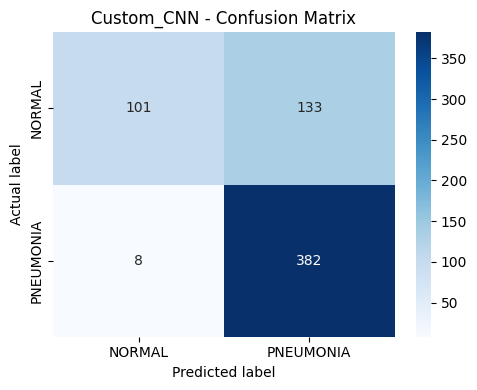

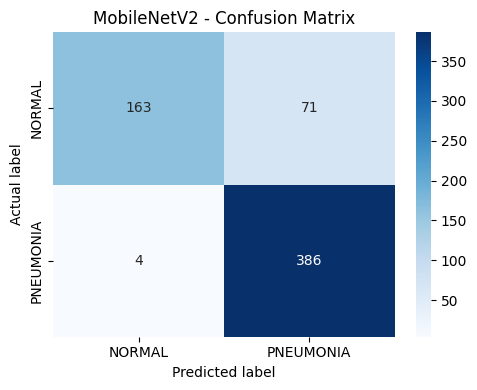

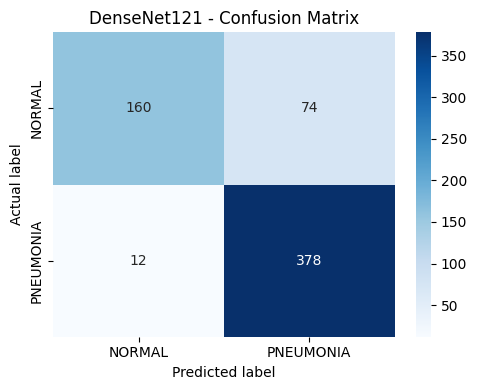

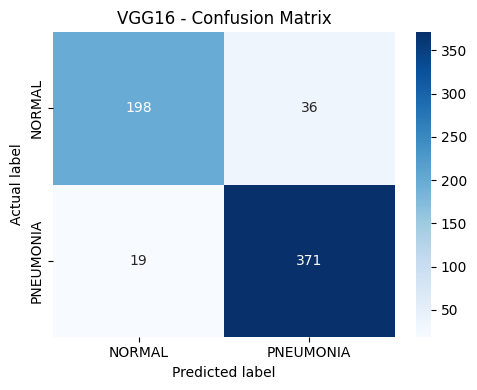

In [39]:
for name, probabilities in all_probabilities.items():
    predictions = (probabilities >= 0.5).astype(int)
    cm = confusion_matrix(y_true, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.savefig(RESULT_DIR / f"{name}_confusion_matrix.png", dpi=150)
    plt.show()

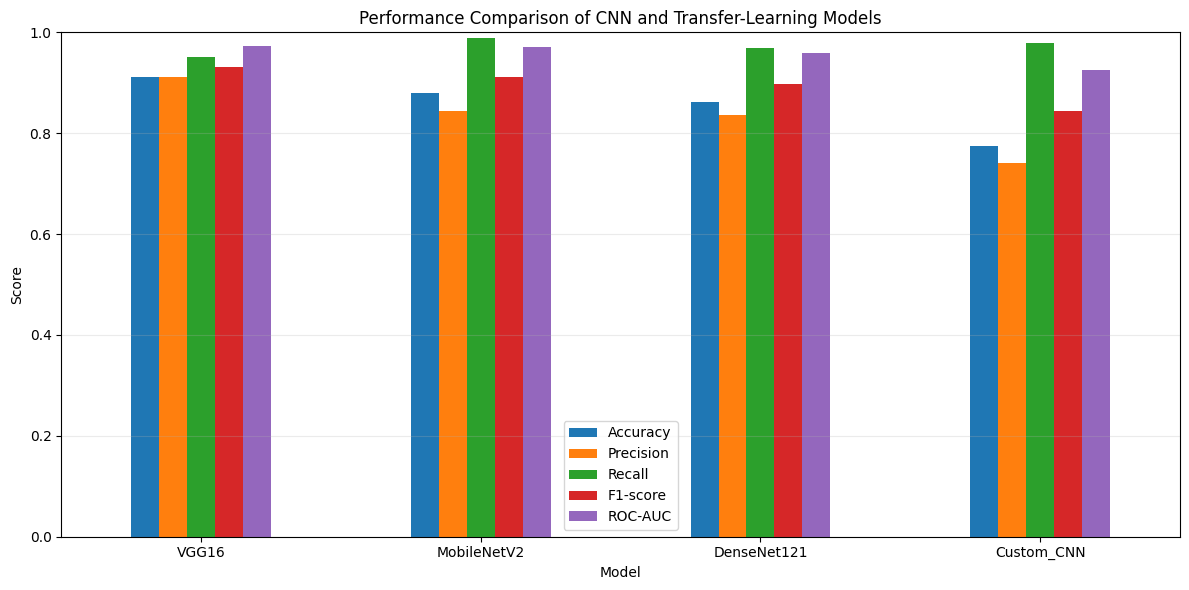

In [40]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = comparison_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0
)
ax.set_title("Performance Comparison of CNN and Transfer-Learning Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULT_DIR / "model_comparison.png", dpi=150)
plt.show()

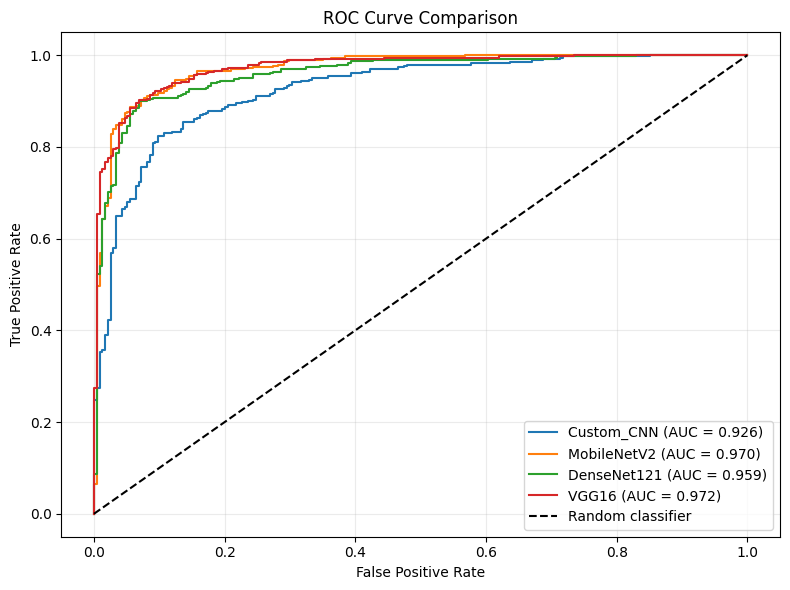

In [41]:
plt.figure(figsize=(8, 6))
for name, probabilities in all_probabilities.items():
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    auc_value = roc_auc_score(y_true, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULT_DIR / "roc_comparison.png", dpi=150)
plt.show()

In [42]:
validation_scores = {}
for name, model in trained_models.items():
    evaluation = model.evaluate(val_ds, verbose=0, return_dict=True)
    validation_scores[name] = float(evaluation["auc"])

best_model_name = max(validation_scores, key=validation_scores.get)
best_model = trained_models[best_model_name]

with open(MODEL_DIR / "best_model.json", "w") as f:
    json.dump({
        "best_model": best_model_name,
        "validation_auc": validation_scores[best_model_name],
        "class_names": CLASS_NAMES
    }, f, indent=4)

print("Best model:", best_model_name)
print("Validation AUC:", round(validation_scores[best_model_name], 4))

Best model: VGG16
Validation AUC: 0.9973


Please upload a chest X-ray image (JPG, JPEG, or PNG):


Saving OIP.webp to OIP.webp


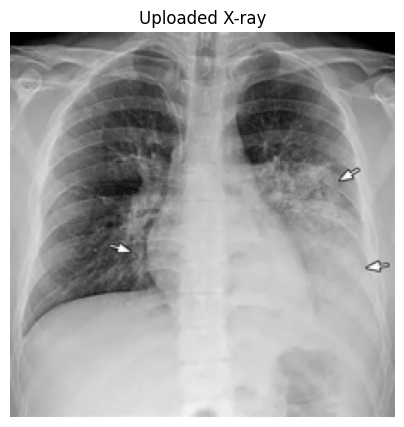

Model-estimated class: NORMAL
NORMAL probability: 56.51%
PNEUMONIA probability: 43.49%
Educational demonstration only — not a medical diagnosis.


In [48]:
from google.colab import files
from PIL import Image
import os

print("Please upload a chest X-ray image (JPG, JPEG, or PNG):")
uploaded_image = files.upload()

if not uploaded_image:
    print("No file uploaded.")
else:
    image_file = next(iter(uploaded_image.keys()))

    # Check if the uploaded file is a valid image type to prevent UnidentifiedImageError
    valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    if not image_file.lower().endswith(valid_extensions):
        print(f"\n[ERROR] You uploaded '{image_file}'. This is not an image!")
        print("Please re-run this cell and upload a valid chest X-ray image file (e.g., .jpeg, .jpg, .png).")
    else:
        img = Image.open(image_file).convert("RGB").resize(IMG_SIZE)
        image_array = np.array(img, dtype=np.float32)
        image_batch = np.expand_dims(image_array, axis=0)

        prob_pneumonia = float(best_model.predict(image_batch, verbose=0)[0][0])
        prob_normal = 1.0 - prob_pneumonia
        predicted_label = "PNEUMONIA" if prob_pneumonia >= 0.5 else "NORMAL"

        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.title("Uploaded X-ray")
        plt.axis("off")
        plt.show()

        print("Model-estimated class:", predicted_label)
        print(f"NORMAL probability: {prob_normal * 100:.2f}%")
        print(f"PNEUMONIA probability: {prob_pneumonia * 100:.2f}%")
        print("Educational demonstration only — not a medical diagnosis.")